# Langgraph

In [1]:
# import necessary modules
import os
from dotenv import load_dotenv
from typing import Annotated
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages



In [2]:
# Load api Key
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [3]:
# Define the state of graph 
class state(TypedDict):
    # add_messages function appends messages to the messages list ( not overwrite ) 
    # in the annotation defines how this state key should be updated
    messages:Annotated[list,add_messages]

In [4]:
# Initializing the chat model
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

# First way to init model
llm_model_1 = ChatGroq(model="llama3-8b-8192")

# Second way to init model
llm_model_2 = init_chat_model(model="groq:openai/gpt-oss-120b")


In [37]:
llm_model_1

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.0', 'langchain': '1.3.17'}}, profile={'name': 'Llama 3 8B', 'status': 'deprecated', 'release_date': '2024-04-18', 'last_updated': '2024-04-18', 'open_weights': True, 'max_input_tokens': 8192, 'max_output_tokens': 8192, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002407F1FC180>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000024002DE9810>, model_name='llama3-8b-8192', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [38]:
llm_model_2

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.0', 'langchain': '1.3.17'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000024002DE8FC0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000024002DEAEA0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
# Defining Node functionality for one of the node in graph ( graph will be created in next steps )
def chatbot(state=state):
    return {"messages":[llm_model_2.invoke(state["messages"])]}

In [7]:
# Defining a graph
graph_builder = StateGraph(state)

# Adding node ( functional piece of graph )
graph_builder.add_node("llm_model",chatbot)

# Adding edges ( edges of graph like start/end )
graph_builder.add_edge(START, "llm_model")
graph_builder.add_edge("llm_model", END)


# Compile the graph
graph = graph_builder.compile()


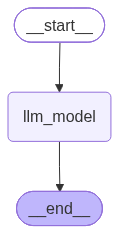

In [41]:
graph

In [42]:
# Invoking graph
response = graph.invoke({"messages":"What is name of our galaxy"})

In [45]:
response["messages"][-1].content

'The galaxy we live in is called the **Milky Way** (often referred to as the **Milky Way Galaxy**). It’s a barred spiral galaxy that contains our Solar System, along with billions of other stars, nebulae, star clusters, and various cosmic structures.'

# Chatbot with tools

In [23]:
# Custom tool
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
# calling few tools from langchain tool set
from langchain_tavily import TavilySearch
from dotenv import load_dotenv

load_dotenv()

tavily_tool=TavilySearch(max_results=2)

def weather_api(latitude=52.52,longitiude=13.41,hourly="temperature_2m"):
    '''Setup the Open-Meteo API client with cache and retry on error. This function gives weather report for given latitude & longitude & hourly'''

    cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
    retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
    openmeteo = openmeteo_requests.Client(session = retry_session)
    # Make sure all required weather variables are listed here
    # The order of variables in hourly or daily is important to assign them correctly below
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitiude,
        "hourly": hourly,
    }
    responses = openmeteo.weather_api(url, params = params)

    # Process first location. Add a for-loop for multiple locations or weather models
    response = responses[0]
    print(f"Coordinates: {abs(response.Latitude())}°{'S' if response.Latitude() < 0 else 'N'} {abs(response.Longitude())}°{'W' if response.Longitude() < 0 else 'E'}")
    print(f"Elevation: {response.Elevation()} m asl")
    print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

    # Process hourly data. The order of variables needs to be the same as requested.
    hourly = response.Hourly()
    hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()

    hourly_data = {
        "date": pd.date_range(
            start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
            end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
            freq = pd.Timedelta(seconds = hourly.Interval()),
            inclusive = "left"
        )
    }

    hourly_data["temperature_2m"] = hourly_temperature_2m

    hourly_dataframe = pd.DataFrame(data = hourly_data)
    return hourly_dataframe

# bind tools with llm
model_with_tools = llm_model_2.bind_tools([tavily_tool,weather_api])



In [24]:
model_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.0', 'langchain': '1.3.17'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000022317BE1450>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022317BE1E50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, a

In [25]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from typing import Annotated
from typing_extensions import TypedDict

class State(TypedDict):
    messages: Annotated[list,add_messages]

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[model_with_tools.invoke(state["messages"])]}

## Graph with nodes 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode([tavily_tool,weather_api]))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()


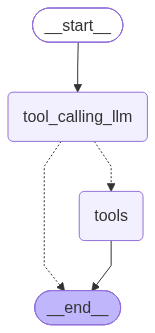

In [26]:
graph

In [28]:
response = graph.invoke({'messages':"What is the tech stack needed for building an AI Agent ?"})

In [33]:
response['messages'][-1].content

'Below is a practical, “battle‑tested” tech‑stack that covers **all the layers you’ll need to design, train, serve, and operate a modern AI Agent** (e.g., a conversational assistant, autonomous tool‑using bot, or multimodal planner).  \nFeel free to cherry‑pick components that fit your budget, expertise, or compliance requirements – the stack is deliberately modular.\n\n---\n\n## 1️⃣ Core Architecture Overview  \n\n```\n┌───────────────────────────────────────────────────────────────────────┐\n│                           USER INTERFACE (UI)                         │\n│  • Web (React/Next.js, Vue, Svelte)   • Mobile (Flutter, React‑Native)│\n│  • Voice (Web Speech API, Alexa, Google Assistant SDK)              │\n└───────────────▲───────────────────────▲───────────────────────▲───────┘\n                │                       │                       │\n                │   HTTP/WS (REST, gRPC, GraphQL)                │\n                ▼                       ▼                       ▼\n┌

In [35]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the tech stack needed for building an AI Agent ?
================================== Ai Message ==================================

Below is a practical, “battle‑tested” tech‑stack that covers **all the layers you’ll need to design, train, serve, and operate a modern AI Agent** (e.g., a conversational assistant, autonomous tool‑using bot, or multimodal planner).  
Feel free to cherry‑pick components that fit your budget, expertise, or compliance requirements – the stack is deliberately modular.

---

## 1️⃣ Core Architecture Overview  

```
┌───────────────────────────────────────────────────────────────────────┐
│                           USER INTERFACE (UI)                         │
│  • Web (React/Next.js, Vue, Svelte)   • Mobile (Flutter, React‑Native)│
│  • Voice (Web Speech API, Alexa, Google Assistant SDK)              │
└───────────────▲───────────────────────▲───────────────────────▲─────

In [38]:
# question related to tool
tool_call_response = graph.invoke({"messages": "What is the weather condition in Noida ? and then tell me When is the chance of rain in Noida?"})

Coordinates: 28.506149291992188°N 77.40614318847656°E
Elevation: 200.0 m asl
Timezone difference to GMT+0: 0s


In [39]:
for m in tool_call_response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the weather condition in Noida ? and then tell me When is the chance of rain in Noida?
================================== Ai Message ==================================
Tool Calls:
  weather_api (fc_79dfbac9-9b3d-47b1-ba27-abfc248efce2)
 Call ID: fc_79dfbac9-9b3d-47b1-ba27-abfc248efce2
  Args:
    hourly: ['temperature_2m', 'precipitation_probability']
    latitude: 28.5355
    longitiude: 77.391
================================= Tool Message =================================
Name: weather_api

                         date  temperature_2m
0   2026-11-15 00:00:00+00:00       20.650000
1   2026-11-15 01:00:00+00:00       20.750000
2   2026-11-15 02:00:00+00:00       20.700001
3   2026-11-15 03:00:00+00:00       21.299999
4   2026-11-15 04:00:00+00:00       23.150000
..                        ...             ...
163 2026-11-21 19:00:00+00:00       13.200000
164 2026-11-21 20:00:00+00:00       12.5000

# Agent with Memory

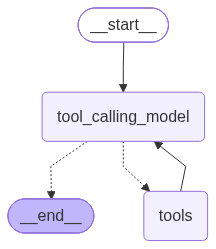

In [44]:
# Agent with Memory 
from langchain import messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver
from typing import Annotated, TypedDict


memory = MemorySaver()

# state for the graph
class State(TypedDict):
    messages: Annotated[list,add_messages]

# tool calling llm node 
def tool_calling_model(state: State):
     return {"messages":[model_with_tools.invoke(state["messages"])]}

# define graph builder 
builder = StateGraph(State)
# add nodes 
builder.add_node('tool_calling_model', tool_calling_model)
builder.add_node('tools', ToolNode([tavily_tool,weather_api]))

# add edges 
builder.add_edge(START,'tool_calling_model')
builder.add_conditional_edges(
    'tool_calling_model',
    tools_condition
)
builder.add_edge('tools', 'tool_calling_model')

# compile graph
graph_with_memory = builder.compile(checkpointer=memory)

graph_with_memory


In [47]:
# config for graph 
config = { 'configurable':{'thread_id': "1"}}

# invoke graph 
respone = graph_with_memory.invoke({
    'messages':"My Name is Anchal, I have few questions for you.What is purpose of langchain & langgraph. What is the current weather condition of Delhi city"}
    ,config)

Coordinates: 28.7170467376709°N 77.05479431152344°E
Elevation: 222.0 m asl
Timezone difference to GMT+0: 0s


In [49]:
for m in respone['messages']:
    m.pretty_print()

================================ Human Message =================================

My Name is Anchal, I have few questions for you.What is purpose of langchain & langgraph. What is the current weather condition of Delhi city
================================== Ai Message ==================================
Tool Calls:
  weather_api (fc_bd56afc2-c67e-48e8-a28c-8e176055711e)
 Call ID: fc_bd56afc2-c67e-48e8-a28c-8e176055711e
  Args:
    hourly: temperature_2m
    latitude: 28.7041
    longitiude: 77.1025
================================= Tool Message =================================
Name: weather_api

                         date  temperature_2m
0   2026-11-15 00:00:00+00:00       20.950001
1   2026-11-15 01:00:00+00:00       20.000000
2   2026-11-15 02:00:00+00:00       20.549999
3   2026-11-15 03:00:00+00:00       21.400000
4   2026-11-15 04:00:00+00:00       22.650000
..                        ...             ...
163 2026-11-21 19:00:00+00:00       15.000000
164 2026-11-21 20:00:00+00:0

In [53]:
response_with_memeory = graph_with_memory.invoke({'messages':'What is my name'},config=config)


In [54]:
def preety_printing(response):
    for message in response['messages']:
        message.pretty_print()

In [55]:
preety_printing(response_with_memeory)

================================ Human Message =================================

My Name is Anchal, I have few questions for you.What is purpose of langchain & langgraph. What is the current weather condition of Delhi city
================================== Ai Message ==================================
Tool Calls:
  weather_api (fc_bd56afc2-c67e-48e8-a28c-8e176055711e)
 Call ID: fc_bd56afc2-c67e-48e8-a28c-8e176055711e
  Args:
    hourly: temperature_2m
    latitude: 28.7041
    longitiude: 77.1025
================================= Tool Message =================================
Name: weather_api

                         date  temperature_2m
0   2026-11-15 00:00:00+00:00       20.950001
1   2026-11-15 01:00:00+00:00       20.000000
2   2026-11-15 02:00:00+00:00       20.549999
3   2026-11-15 03:00:00+00:00       21.400000
4   2026-11-15 04:00:00+00:00       22.650000
..                        ...             ...
163 2026-11-21 19:00:00+00:00       15.000000
164 2026-11-21 20:00:00+00:0

In [56]:
response_with_memeory['messages'][-1].content

'Your name is **Anchal**.'

# Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.\
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.\
updates : This streams updates to the state of the graph after each node is called.

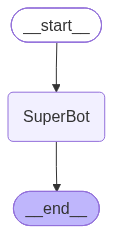

In [57]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

def superbot(state:State):
    return {"messages":[model_with_tools.invoke(state['messages'])]}

graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)

## Edges
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))




In [61]:
## Invocation
config = {"configurable": {"thread_id": "1"}}
graph_builder.invoke({'messages':"Hi,My name is Anchal.S And I like cricket"},config)


# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Anchal.S And I like cricket"},config,stream_mode="updates"):
    print(chunk)


{'SuperBot': {'messages': [AIMessage(content='', additional_kwargs={'reasoning_content': 'User repeats greeting. Possibly wants info about cricket. We searched latest cricket news. Need to retrieve results.', 'tool_calls': [{'id': 'fc_35c98679-3406-4de2-9888-7cc267608aac', 'function': {'arguments': '{"query":"latest cricket news November 2026","search_depth":"fast","time_range":"day"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 813, 'total_tokens': 876, 'completion_time': 0.13447989, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.105621883, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.157416556, 'total_time': 0.240101773}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c3da0d4bb9', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e067-82e1-7fb3-ad53-997f1d528550-0', tool_c

In [62]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)


{'messages': [HumanMessage(content='Hi,My name is Anchal.S And I like cricket', additional_kwargs={}, response_metadata={}, id='4690576a-c5c6-4115-8d5f-5b994c4d6cac'), AIMessage(content='Hello Anchal\u202fS! 👋 Great to meet you.  \n\nCricket is such an exciting sport—whether you love the drama of Test matches, the fast‑paced action of T20, or the classic charm of One‑Day Internationals, there’s always something to talk about.\n\nDo you have a favorite team or player? Are you following any series right now (e.g., the IPL, the Ashes, World Cup qualifiers)? Let me know what you’re most interested in, and we can dive into stats, recent matches, upcoming fixtures, or even some fun cricket trivia!', additional_kwargs={'reasoning_content': 'User says hi, introduces name and likes cricket. Probably respond friendly, ask about preferences, maybe ask about cricket topics. No need for tools.'}, response_metadata={'token_usage': {'completion_tokens': 160, 'prompt_tokens': 404, 'total_tokens': 564,

In [63]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='0435897d-ddac-4ec9-b28c-714d0edef120'), AIMessage(content='Hey Krish! 👋 Great to meet you.  \n\nI’m a big fan of cricket too—whether it’s the excitement of a Test match, the fast‑paced drama of a T20, or the strategy of an ODI, there’s always something to love.  \n\nDo you have a favorite team, player, or format? Any recent matches that caught your eye? Let’s chat cricket!', additional_kwargs={'reasoning_content': 'We need to respond. The user says hi, introduces themselves. Probably a friendly greeting, ask about cricket? Should respond.'}, response_metadata={'token_usage': {'completion_tokens': 116, 'prompt_tokens': 403, 'total_tokens': 519, 'completion_time': 0.241255354, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.020396685, 'prompt_tokens_details': None, 'queue_time': 0.318556995, 'total_time': 0.261652039}, 'model_name': 'openai/

In [64]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1e068-c50e-7201-8f65-41130487a69c', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='7d8fa192-8a23-405f-92dc-5c7fa21ed5c4')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1e068-c519-72b2-a6cb-641048660e91', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:17132c9b-fa65-0b17-7452-e6fce23e7dd1'}, 'parent_ids': ['01a1e068-c50e-7201-8f65-41130487a69c']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':